# Pandas for time series

In [2]:
import numpy as np
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as plt
import yfinance as yf

In [3]:
#df = pd.read_csv("../Data files/sp500_stocks.csv")
#df.head()

# download apple data for a specific daterange
df = yf.download("AAPL", start="2020-01-01", end="2024-01-01")
df.head()

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2020-01-02,72.271553,72.331709,71.029930,71.282583,135480400
2020-01-03,71.568893,72.326859,71.345115,71.501519,146322800
2020-01-06,72.139198,72.177699,70.442799,70.693051,118387200
2020-01-07,71.799919,72.403881,71.580950,72.148820,108872000
2020-01-08,72.954926,73.255706,71.503960,71.503960,132079200


In [7]:
print(df.columns)

MultiIndex([( 'Close', 'AAPL'),
            (  'High', 'AAPL'),
            (   'Low', 'AAPL'),
            (  'Open', 'AAPL'),
            ('Volume', 'AAPL')],
           names=['Price', 'Ticker'])


In [4]:
ticker = "AAPL"

In [9]:
#df_stock = df[df["Ticker"] == ticker]

#df_stock.head()

df_stock = df

In [11]:
#type(df_stock["Date"].iloc[0])
type(df_stock["Date"])

KeyError: 'Date'

In [53]:
df_stock['Date'] = df_stock['Date'].apply(pd.to_datetime)
#df_stock = df_stock.drop(columns=["Date"])
df_stock.head()

C:\Users\ajacquie\AppData\Local\Temp\ipykernel_12704\3081672581.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_stock['Date'] = df_stock['Date'].apply(pd.to_datetime)


,Date,Symbol,Adj Close,Close,High,Low,Open,Volume
145314,2010-01-04,AAPL,6.454505,7.643214,7.660714,7.585000,7.622500,493729600.0
145315,2010-01-05,AAPL,6.465664,7.656429,7.699643,7.616071,7.664286,601904800.0
145316,2010-01-06,AAPL,6.362821,7.534643,7.686786,7.526786,7.656429,552160000.0
145317,2010-01-07,AAPL,6.351057,7.520714,7.571429,7.466071,7.562500,477131200.0
145318,2010-01-08,AAPL,6.393281,7.570714,7.571429,7.466429,7.510714,447610800.0


In [54]:
type(df_stock["Date"].iloc[0])

pandas._libs.tslibs.timestamps.Timestamp

In [55]:
df_stock.set_index('Date',inplace=True)
df_stock.head()

,Symbol,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,,
2010-01-04,AAPL,6.454505,7.643214,7.660714,7.585000,7.622500,493729600.0
2010-01-05,AAPL,6.465664,7.656429,7.699643,7.616071,7.664286,601904800.0
2010-01-06,AAPL,6.362821,7.534643,7.686786,7.526786,7.656429,552160000.0
2010-01-07,AAPL,6.351057,7.520714,7.571429,7.466071,7.562500,477131200.0
2010-01-08,AAPL,6.393281,7.570714,7.571429,7.466429,7.510714,447610800.0


In [56]:
df_stock.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3726 entries, 2010-01-04 to 2024-10-22
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Symbol     3726 non-null   object 
 1   Adj Close  3726 non-null   float64
 2   Close      3726 non-null   float64
 3   High       3726 non-null   float64
 4   Low        3726 non-null   float64
 5   Open       3726 non-null   float64
 6   Volume     3726 non-null   float64
dtypes: float64(6), object(1)
memory usage: 232.9+ KB


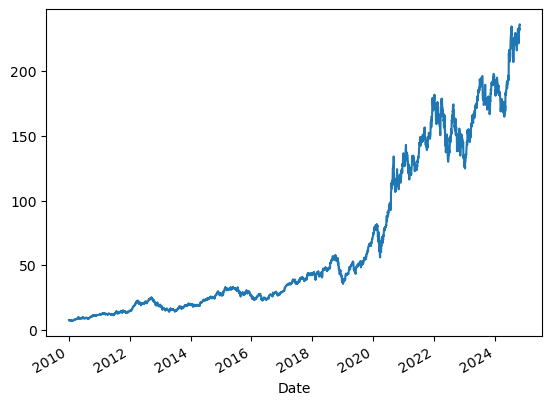

In [57]:
df_stock["Close"].plot();

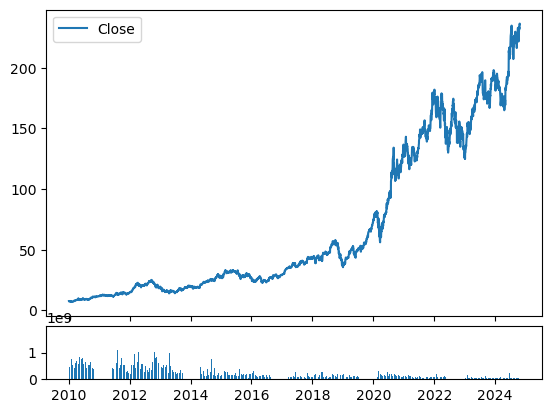

In [64]:
# Visualize the close prices, 100ma, and volume
ax1 = plt.subplot2grid((6,1), (0,0), rowspan=5, colspan=1)
ax2 = plt.subplot2grid((6,1), (5,0), rowspan=1, colspan=1, sharex=ax1)

ax1.plot(df_stock.index, df_stock["Close"], label='Close')
ax2.bar(df_stock.index, df_stock['Volume'], label='Volume')
ax1.legend(loc="best")
plt.show()

Let's only keep the Close price

In [13]:
df_asset = df_stock[["Close"]]
df_asset = df_asset.rename(columns={df_asset.columns[0]: ticker})
df_asset.head()

,AAPL
Date,
2010-01-04,7.643214
2010-01-05,7.656429
2010-01-06,7.534643
2010-01-07,7.520714
2010-01-08,7.570714


In [14]:
df_spx = pd.read_csv("../Data files/sp500_index.csv")
df_spx.head()

,Date,S&P500
0,2014-09-30,1972.29
1,2014-10-01,1946.16
2,2014-10-02,1946.17
3,2014-10-03,1967.90
4,2014-10-06,1964.82


In [15]:
df_spx = df_spx.rename(columns={df_spx.columns[1]: "SPX"})
df_spx['Date'] = df_spx['Date'].apply(pd.to_datetime)
df_spx.set_index('Date',inplace=True)
df_spx.head()

,SPX
Date,
2014-09-30,1972.29
2014-10-01,1946.16
2014-10-02,1946.17
2014-10-03,1967.90
2014-10-06,1964.82


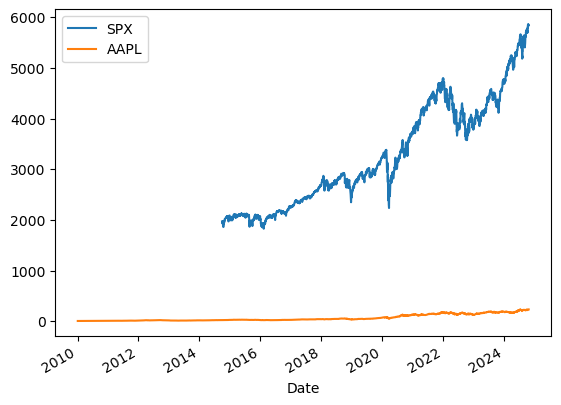

In [16]:
df_spx["SPX"].plot(label="SPX")
df_asset[ticker].plot(label=ticker)
plt.legend(loc="best")
plt.show()

# Time Resampling

In [17]:
df_spx_extract = df_spx.resample(rule='W').mean()

In [18]:
df_spx_extract.head()

,SPX
Date,
2014-10-05,1958.130
2014-10-12,1940.630
2014-10-19,1872.890
2014-10-26,1937.560
2014-11-02,1988.336


### Custom resampling

In [19]:
def my_resampling(data_series):
    """
    ......Details.....
    """
    return data_series[len(data_series)//2]
    
df_spx.resample(rule='W').apply(my_resampling).head()

C:\Users\ajacquie\AppData\Local\Temp\ipykernel_12704\790202808.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  return data_series[len(data_series)//2]


,SPX
Date,
2014-10-05,1946.17
2014-10-12,1968.89
2014-10-19,1862.49
2014-10-26,1927.11
2014-11-02,1982.30


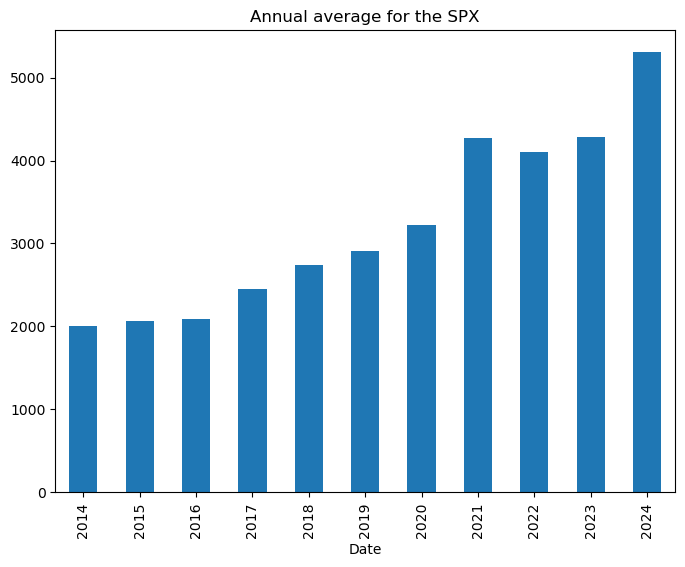

In [20]:
df_spx_annual = df_spx['SPX'].resample('A').mean()
plt.figure(figsize=(8,6))
df_spx_annual.plot(kind='bar')
plt.title('Annual average for the SPX');
x_labels = df_spx_annual.index.strftime('%Y')
plt.xticks(range(len(df_spx_annual)), x_labels)
plt.show()

# Rolling

<Axes: title={'center': 'Rolling mean'}, xlabel='Date'>

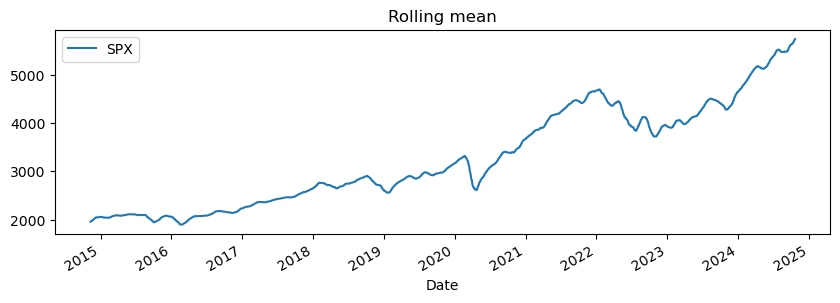

In [42]:
df_spx.rolling(window=30).mean().plot(figsize=(10,3), title="Rolling mean")

<Axes: xlabel='Date'>

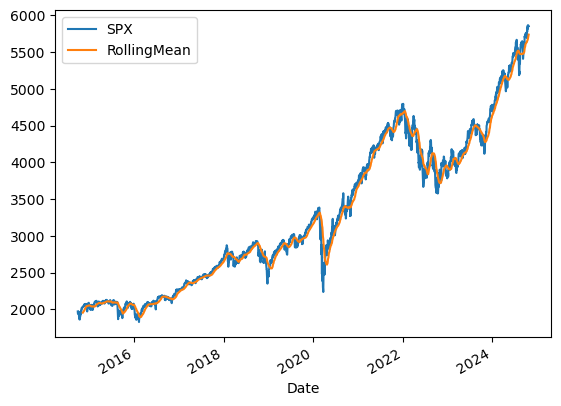

In [43]:
df_spx["RollingMean"] = df_spx.rolling(window=30).mean()
df_spx[["SPX", "RollingMean"]].plot()

### Bolling bands

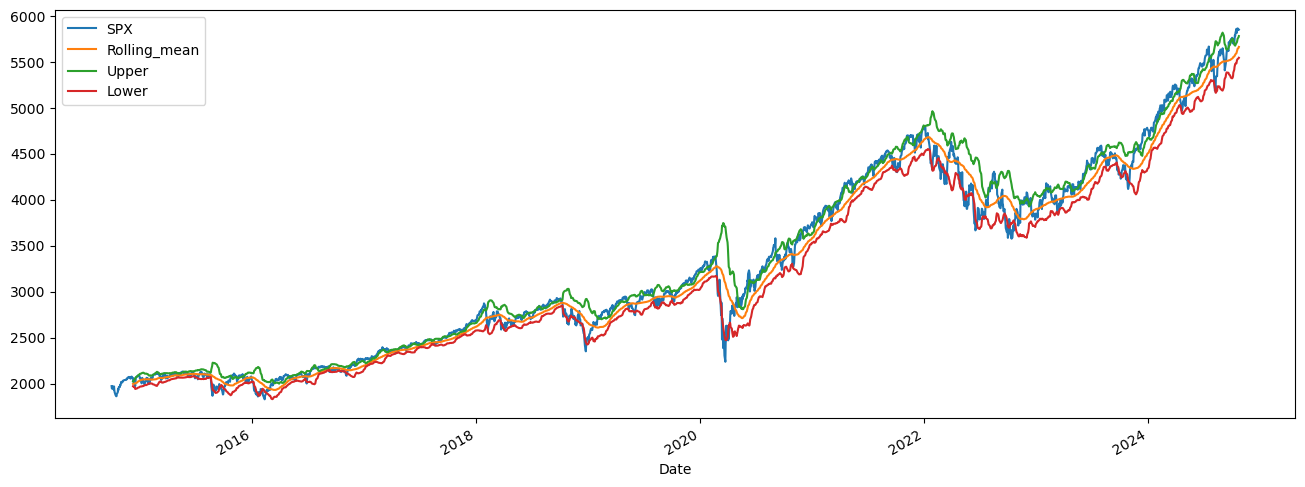

In [47]:
# Close 20 MA
df_spx['Rolling_mean'] = df_spx['SPX'].rolling(window=50).mean()
# Upper = 20MA + 2*std(20)
df_spx['Upper'] = df_spx['Rolling_mean'] + 2*df_spx['SPX'].rolling(window=20).std()
# Lower = 20MA + 2*std(20)
df_spx['Lower'] = df_spx['Rolling_mean'] - 2*df_spx['SPX'].rolling(window=20).std()
#  Close
df_spx[['SPX','Rolling_mean','Upper','Lower']].plot(figsize=(16,6))
plt.show()